In [3]:
from google.colab import userdata
import os

os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

!pip install -q kaggle
!kaggle datasets download -d datamunge/sign-language-mnist
!unzip -q sign-language-mnist.zip -d sign_language_mnist

Dataset URL: https://www.kaggle.com/datasets/datamunge/sign-language-mnist
License(s): CC0-1.0
100% 62.6M/62.6M [00:00<00:00, 245MB/s]



In [4]:
!ls sign_language_mnist

american_sign_language.PNG  sign_mnist_test	 sign_mnist_train.csv
amer_sign2.png		    sign_mnist_test.csv
amer_sign3.png		    sign_mnist_train


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import PIL.Image, PIL.ImageFont, PIL.ImageDraw
import tensorflow as tf

train_df = pd.read_csv('sign_language_mnist/sign_mnist_train.csv')
test_df = pd.read_csv('sign_language_mnist/sign_mnist_test.csv')

train_labels = train_df['label'].values.astype(np.int64)
train_images = train_df.drop('label', axis=1).values.astype(np.float32)
train_images = train_images.reshape(-1, 28, 28)

test_labels = test_df['label'].values.astype(np.int64)
test_images = test_df.drop('label', axis=1).values.astype(np.float32)
test_images = test_images.reshape(-1, 28, 28)

NUM_CLASSES = 25  # sign language mnist uses labels 0-24 (no J, no Z, since they need motion)

print(train_images.shape, train_labels.shape)

(27455, 28, 28) (27455,)


In [6]:
im_width = 75
im_height = 75

def display_digits_with_boxes(images, predictions, labels, pred_bboxes, bboxes, iou, title):
    n = 10
    indexes = np.random.choice(len(predictions), size=n)
    n_images = images[indexes]
    n_predictions = predictions[indexes]
    n_labels = labels[indexes]

    n_iou = []
    if len(iou) > 0:
        n_iou = iou[indexes]

    n_pred_bboxes = pred_bboxes[indexes] if len(pred_bboxes) > 0 else []
    n_bboxes = bboxes[indexes] if len(bboxes) > 0 else []

    n_images = n_images * 255.0
    n_images = n_images.reshape(n, 75, 75)
    fig = plt.figure(figsize=(20, 4))
    plt.title(title)
    plt.xticks([])
    plt.yticks([])

    for i in range(10):
        ax = fig.add_subplot(1, 10, i+1)
        bboxes_to_plot = []
        if len(n_pred_bboxes) > i:
            bboxes_to_plot.append(n_pred_bboxes[i])
        if len(n_bboxes) > i:
            bboxes_to_plot.append(n_bboxes[i])

        img_to_draw = draw_bounding_boxes_on_image_array(
            image=n_images[i], boxes=np.asarray(bboxes_to_plot), color=['red', 'green'])
        plt.xticks([])
        plt.yticks([])
        plt.imshow(img_to_draw)

        if n_predictions[i] != n_labels[i]:
            ax.xaxis.label.set_color('red')
        plt.xlabel(f"pred={n_predictions[i]}, label={n_labels[i]}")

        if len(n_iou) > i:
            color = "green" if n_iou[i][0] > 0.6 else "red"
            ax.text(0.2, -0.3, "iou: %s" % (n_iou[i][0]), color=color, transform=ax.transAxes)


def draw_bounding_boxes_on_image_array(image, boxes, color=[], thickness=1, display_str_list=()):
    image_pil = PIL.Image.fromarray(np.uint8(image)).convert('RGB')
    draw_bounding_boxes_on_image(image_pil, boxes, color, thickness, display_str_list)
    return np.array(image_pil)


def draw_bounding_boxes_on_image(image, boxes, color=[], thickness=1, display_str_list=()):
    boxes_shape = boxes.shape
    if not boxes_shape:
        return
    if len(boxes_shape) != 2 or boxes_shape[1] != 4:
        raise ValueError('Input must be of size [N,4]')
    for i in range(boxes_shape[0]):
        c = color[i] if i < len(color) else 'red'
        draw_bounding_box_on_image(image, boxes[i][1], boxes[i][0], boxes[i][3], boxes[i][2], color=c, thickness=thickness)


def draw_bounding_box_on_image(image, ymin, xmin, ymax, xmax, color='red', thickness=1):
    draw = PIL.ImageDraw.Draw(image)
    im_width, im_height = image.size
    (left, right, top, bottom) = (xmin * im_width, xmax * im_width, ymin * im_height, ymax * im_height)
    draw.line([(left, top), (left, bottom), (right, bottom), (right, top), (left, top)], width=thickness, fill=color)

In [7]:
def read_image_kaggle(image, label):
    xmin = tf.random.uniform((), 0, im_width - 28, dtype=tf.int32)
    ymin = tf.random.uniform((), 0, im_height - 28, dtype=tf.int32)

    image = tf.reshape(image, (28, 28, 1))
    image = tf.image.pad_to_bounding_box(image, ymin, xmin, im_height, im_width)
    image = tf.cast(image, tf.float32) / 255.0

    xmin = tf.cast(xmin, tf.float32)
    ymin = tf.cast(ymin, tf.float32)

    xmax = (xmin + 28) / im_width
    ymax = (ymin + 28) / im_height
    xmin = xmin / im_width
    ymin = ymin / im_height

    label = tf.one_hot(label, NUM_CLASSES)
    return image, (label, [xmin, ymin, xmax, ymax])

In [8]:
BATCH_SIZE = 64

def get_training_dataset():
    dataset = tf.data.Dataset.from_tensor_slices((train_images, train_labels))
    dataset = dataset.map(read_image_kaggle, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.shuffle(5000, reshuffle_each_iteration=True)
    dataset = dataset.repeat()
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

def get_validation_dataset():
    dataset = tf.data.Dataset.from_tensor_slices((test_images, test_labels))
    dataset = dataset.map(read_image_kaggle, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(len(test_images))
    dataset = dataset.repeat()
    return dataset

training_dataset = get_training_dataset()
validation_dataset = get_validation_dataset()

In [9]:
def feature_extractor(inputs):
    x = tf.keras.layers.Conv2D(16, activation='relu', kernel_size=3, input_shape=(75, 75, 1))(inputs)
    x = tf.keras.layers.AveragePooling2D((2, 2))(x)
    x = tf.keras.layers.Conv2D(32, kernel_size=3, activation='relu')(x)
    x = tf.keras.layers.AveragePooling2D((2, 2))(x)
    x = tf.keras.layers.Conv2D(64, kernel_size=3, activation='relu')(x)
    x = tf.keras.layers.AveragePooling2D((2, 2))(x)
    return x

def dense_layers(x):
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    return x

def classifier(x):
    return tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='classification')(x)

def bounding_box_regression(x):
    return tf.keras.layers.Dense(4, name='bounding_box')(x)

def build_model():
    inputs = tf.keras.layers.Input(shape=(75, 75, 1))
    feats = feature_extractor(inputs)
    dense = dense_layers(feats)
    class_out = classifier(dense)
    box_out = bounding_box_regression(dense)
    model = tf.keras.Model(inputs=inputs, outputs=[class_out, box_out])
    return model

model = build_model()
model.compile(
    optimizer='adam',
    loss={'classification': 'categorical_crossentropy', 'bounding_box': 'mse'},
    metrics={'classification': 'accuracy', 'bounding_box': 'mse'}
)
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 75, 75, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 73, 73,    │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d   │ (None, 36, 36,    │          0 │ conv2d[0][0]      │
│ (AveragePooling2D)  │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 34, 34,    │      4,640 │ average_pooling2… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_1 │ (None, 17, 17,    │          0 │ conv2d_1[0][0]    │
│ (AveragePooling2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 15, 15,    │     18,496 │ average_pooling2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling2d_2 │ (None, 7, 7, 64)  │          0 │ conv2d_2[0][0]    │
│ (AveragePooling2D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3136)      │          0 │ average_pooling2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    401,536 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classification      │ (None, 25)        │      3,225 │ dense[0][0]       │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bounding_box        │ (None, 4)         │        516 │ dense[0][0]       │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 428,573 (1.63 MB)

 Trainable params: 428,573 (1.63 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
EPOCHS = 10
steps_per_epoch = len(train_images) // BATCH_SIZE
validation_steps = 1

history = model.fit(
    training_dataset,
    steps_per_epoch=steps_per_epoch,
    validation_data=validation_dataset,
    validation_steps=validation_steps,
    epochs=EPOCHS
)

Epoch 1/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - bounding_box_loss: 0.0068 - bounding_box_mse: 0.0068 - classification_accuracy: 0.0518 - classification_loss: 3.1741 - loss: 3.1809 - val_bounding_box_loss: 0.0046 - val_bounding_box_mse: 0.0046 - val_classification_accuracy: 0.0414 - val_classification_loss: 3.1518 - val_loss: 3.1564
Epoch 2/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - bounding_box_loss: 0.0072 - bounding_box_mse: 0.0072 - classification_accuracy: 0.1360 - classification_loss: 2.8251 - loss: 2.8323 - val_bounding_box_loss: 0.0079 - val_bounding_box_mse: 0.0079 - val_classification_accuracy: 0.1690 - val_classification_loss: 2.6645 - val_loss: 2.6724
Epoch 3/10
428/428 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - bounding_box_loss: 0.0069 - bounding_box_mse: 0.0069 - classification_accuracy: 0.3189 - classification_loss: 2.0151 - loss: 2.0220 - val_bounding_box_loss: 0.0064 - val_bounding_box_mse: 0.0064 - val_classification_accuracy: 0.3344 - val_classification_loss: 1.

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


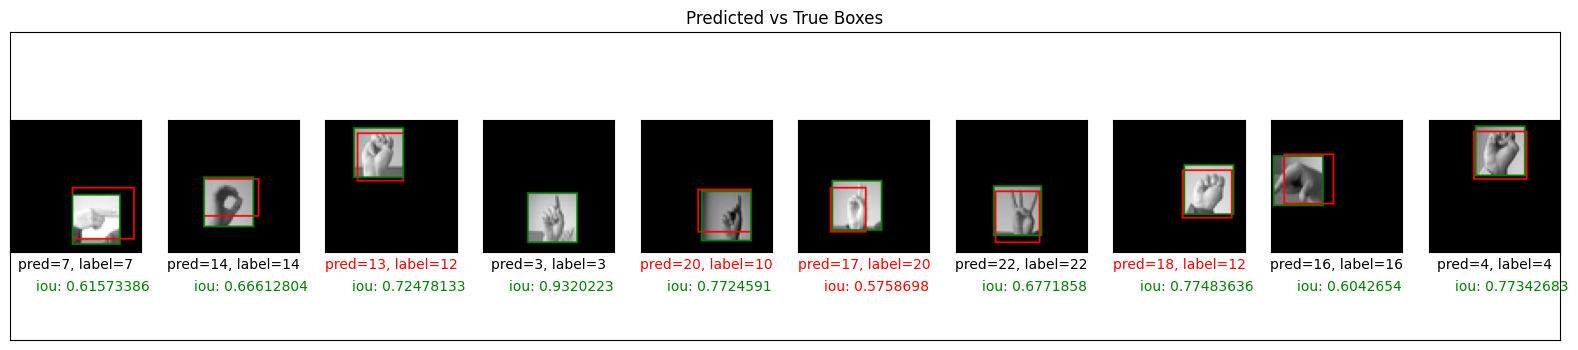

In [14]:
def intersection_over_union(pred_box, true_box):
    xmin_p, ymin_p, xmax_p, ymax_p = np.split(pred_box, 4, axis=1)
    xmin_t, ymin_t, xmax_t, ymax_t = np.split(true_box, 4, axis=1)

    smoothing = 1e-10
    xmin_overlap = np.maximum(xmin_p, xmin_t)
    ymin_overlap = np.maximum(ymin_p, ymin_t)
    xmax_overlap = np.minimum(xmax_p, xmax_t)
    ymax_overlap = np.minimum(ymax_p, ymax_t)

    pred_area = (xmax_p - xmin_p) * (ymax_p - ymin_p)
    true_area = (xmax_t - xmin_t) * (ymax_t - ymin_t)

    overlap_area = np.maximum((xmax_overlap - xmin_overlap), 0) * np.maximum((ymax_overlap - ymin_overlap), 0)
    union_area = (pred_area + true_area) - overlap_area

    iou = (overlap_area + smoothing) / (union_area + smoothing)
    return iou

val_imgs, (val_labels_oh, val_boxes) = next(iter(validation_dataset))
predictions = model.predict(val_imgs)
pred_labels = np.argmax(predictions[0], axis=1)
pred_boxes = predictions[1]

true_labels = np.argmax(val_labels_oh.numpy(), axis=1)
true_boxes = np.array(val_boxes).T

iou = intersection_over_union(pred_boxes, true_boxes.T)

display_digits_with_boxes(
    val_imgs.numpy(), pred_labels, true_labels,
    pred_boxes, true_boxes.T, iou, "Predicted vs True Boxes"
)